# Spectrum sampling: starter

A hidden spectrum has a few narrow peaks. You decide **which wavelengths** to measure and **for how long**, within a time budget, then submit a 512-point reconstruction. Your score is your error divided by the error of a simple baseline: 1.0 matches the baseline, 0.5 means half its error.

You build two pieces:

- a **surrogate**: a model that turns everything measured so far into an estimate of the spectrum, and how unsure it is;
- a **policy**: the decision maker. From what has been measured and the time left, it chooses the next stage of queries, or stops.

They work in a loop: the policy picks a stage, the server measures it, the surrogate learns from it, and the policy picks again. The surrogate's last estimate is what gets graded.

You may look at the data as often as you like, but **every request costs a little of the same time budget** (`session.request_cost`), however many queries it holds. Looking often lets you adapt sooner and leaves less time to measure.

- **Train** as often as you like, offline or on the server, with any seed.
- **Test** runs your strategy on 10 hidden spectra. The last cell prints your result table. Hand in this notebook: your code and that table are what is graded.

In [ ]:
SERVER = "https://spectrum-server-production.up.railway.app"  
try:
    import spectrum_client as sc
except ImportError:
    %pip install -q "git+https://github.com/YOUR-ORG/YOUR-REPO.git"  
    import spectrum_client as sc

from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.optimize import least_squares
from spectrum_sim import SpectrumEnv, evaluate

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 100})
server = sc.Server(SERVER)
E = sc.E_GRID

connected to https://spectrum-server-production.up.railway.app: time budget 500, each request costs 5, up to 1000 queries per run, test mode on


## 1. One run, by hand

In [ ]:
session = server.train_session(seed=7)
print(session.measure(wavelength=3.0, time=1.0))
print("time left:", session.time_remaining, "| requests so far:", session.rounds_used, "| cost of a request:", session.request_cost)

{'wavelength': 3.0, 'measurement_time': 1.0, 'intensity': 0.3192585190191032, 'time_used': 6.0, 'time_remaining': 494.0, 'rounds_remaining': None}
time left: 494.0 | requests so far: 1 | cost of a request: 5.0


A measurement returns one noisy number and spends its time from the budget, plus the cost of the request. `measure_many` sends a whole stage of queries in one request, so you pay that cost once. Send queries one by one only when the next choice depends on the last result.

## 2. The two pieces and the loop

The **surrogate** takes the data so far, `wl` (wavelengths), `t` (durations) and `v` (intensities), and returns an estimate on all 512 points of `E` plus an uncertainty. The **policy** takes the current state and returns the next stage as a list of `(wavelength, time)` pairs, or `None` to stop. `run` is the loop that joins them.

The baseline, written in this form: a smoother as the surrogate, and a policy that spends all the time in one even scan.

In [ ]:
def smooth_surrogate(wl, t, v, width=0.04):
    """Data so far -> (estimate of the spectrum on E, uncertainty). Nearby, long measurements count more."""
    if len(wl) == 0:
        return np.zeros(len(E)), np.ones(len(E))
    k = np.exp(-0.5 * ((E[:, None] - wl[None, :]) / width) ** 2) * t
    weight = k.sum(1) + 1e-9
    return (k @ v) / weight, 1 / np.sqrt(weight)  # uncertainty here: how little data is near each point


def scan_policy(state, n=250):
    """One stage: spread all the time evenly over n wavelengths, then stop. This is the baseline."""
    if state["stage"] > 0:
        return None
    spendable = state["time_left"] - state["request_cost"]
    return [(w, spendable / n) for w in np.linspace(0, 10, n)]


def run(session, policy, surrogate):
    """The loop: the policy picks a stage, the server measures it, the surrogate learns, repeat."""
    wl, t, v = np.empty(0), np.empty(0), np.empty(0)
    estimate, uncertainty = surrogate(wl, t, v)
    stage_of = []
    for stage in range(100):
        state = {"wl": wl, "t": t, "v": v, "estimate": estimate, "uncertainty": uncertainty, "stage": stage,
                 "time_left": session.time_remaining, "request_cost": session.request_cost}
        queries = policy(state)
        if queries is None or len(queries) == 0:
            break
        results = session.measure_many(queries)
        wl = np.append(wl, [r["wavelength"] for r in results])
        t = np.append(t, [r["measurement_time"] for r in results])
        v = np.append(v, [r["intensity"] for r in results])
        estimate, uncertainty = surrogate(wl, t, v)
        stage_of += [stage] * len(results)
    session.stage_of = stage_of  # only so the figures below can colour each stage
    return estimate

{'accepted': True, 'rmse': 0.024489966717072213, 'reference_rmse': 0.01992023290156903, 'ratio': 1.2294016258787437, 'time_used': 500.0000000000017, 'measurements': 250, 'rounds': 1}


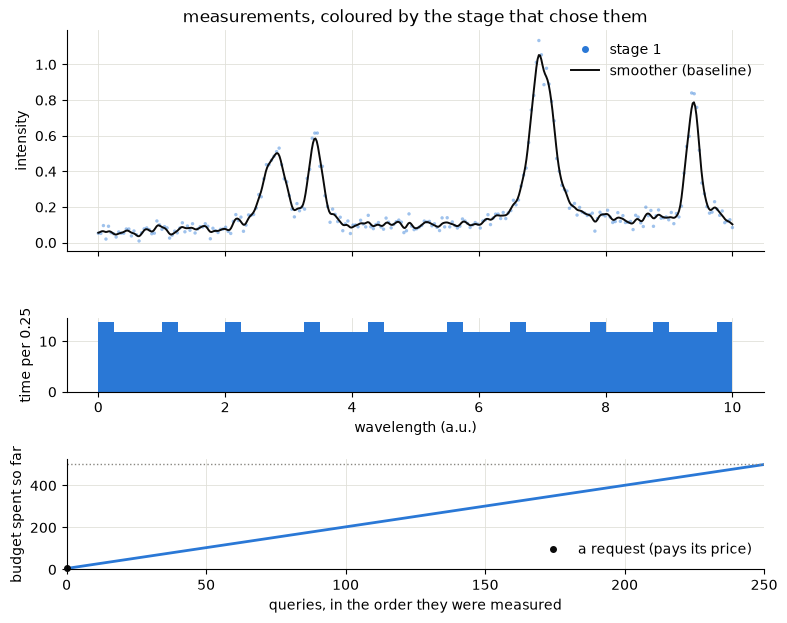

In [ ]:
STAGE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
LINE_STYLES = [("#0b0b0b", "-"), ("#6b6a65", "--")]


def measured(s):
    """Wavelengths, durations and intensities of everything measured in this session."""
    return np.array([[m.wavelength, m.time, m.intensity] for m in s.history]).T


def show(s, predictions):
    """Measurements and prediction(s); time per wavelength; and the budget spent so far, query by query."""
    wl, t, v = measured(s)
    stage = np.array(getattr(s, "stage_of", [0] * len(wl)))
    color = lambda k: STAGE_COLORS[k] if k < len(STAGE_COLORS) else "#898781"  # noqa: E731
    stages = sorted(set(stage))
    bins = np.linspace(0, 10, 41)
    fig = plt.figure(figsize=(9, 7))
    grid = fig.add_gridspec(3, 1, height_ratios=[3, 1, 1.5], hspace=0.5)
    top = fig.add_subplot(grid[0])
    bottom = fig.add_subplot(grid[1], sharex=top)
    clock = fig.add_subplot(grid[2])
    top.tick_params(labelbottom=False)
    top.scatter(wl, v, s=6, c=[color(k) for k in stage], alpha=0.45, lw=0)
    for (label, prediction), (c, ls) in zip(predictions.items(), LINE_STYLES):
        top.plot(E, prediction, color=c, ls=ls, lw=1.4)
    below = np.zeros(len(bins) - 1)
    for k in stages:
        height = below + np.histogram(wl[stage == k], bins, weights=t[stage == k])[0]
        bottom.stairs(height, bins, baseline=below, fill=True, color=color(k), lw=0)
        below = height
    handles = [Line2D([], [], color=color(k), marker="o", ms=4, lw=0) for k in stages]
    handles += [Line2D([], [], color=c, ls=ls, lw=1.4) for _, (c, ls) in zip(predictions, LINE_STYLES)]
    top.legend(handles, [f"stage {k + 1}" for k in stages] + list(predictions), loc="upper right", frameon=False)
    top.set(ylabel="intensity", title="measurements, coloured by the stage that chose them")
    bottom.set(xlabel="wavelength (a.u.)", ylabel="time per 0.25")
    asked, spent, requests = 0, 0.0, []  # queries sent so far, budget spent so far, where requests were paid
    for k in stages:
        durations = t[stage == k]
        requests.append((asked, spent + s.request_cost))  # a request pays its price before its queries start
        spent += s.request_cost
        clock.plot(asked + np.arange(len(durations) + 1), spent + np.append(0, np.cumsum(durations)), color=color(k), lw=2)
        asked += len(durations)
        spent += durations.sum()
    clock.plot(*zip(*requests), "o", color="#0b0b0b", ms=4, clip_on=False, label="a request (pays its price)")
    clock.axhline(s.time_budget, color="#898781", ls=":", lw=1)
    clock.legend(loc="lower right", frameon=False)
    clock.set(xlim=(0, asked), ylim=(0, 1.05 * s.time_budget), xlabel="queries, in the order they were measured", ylabel="budget spent so far")
    plt.show()


session = server.train_session(seed=7)
prediction = run(session, scan_policy, smooth_surrogate)
print(session.submit(prediction))
show(session, {"smoother (baseline)": prediction})

One run is one noisy draw, so its ratio scatters around 1.0. Averaged over many spectra the baseline scores about 1.0.

## 3. A better surrogate

The smoother knows nothing about spectra. This surrogate knows a spectrum is a few peaks on a tilted baseline: it fits Gaussians, and chooses how many by BIC. The starting values and bounds are guesses from looking at spectra, so change them if you can do better. It uses the same scan, so any difference you see comes from the surrogate alone.

{'accepted': True, 'rmse': 0.01460217557955251, 'reference_rmse': 0.01992023290156903, 'ratio': 0.7330323722471317, 'time_used': 500.0000000000017, 'measurements': 250, 'rounds': 1}


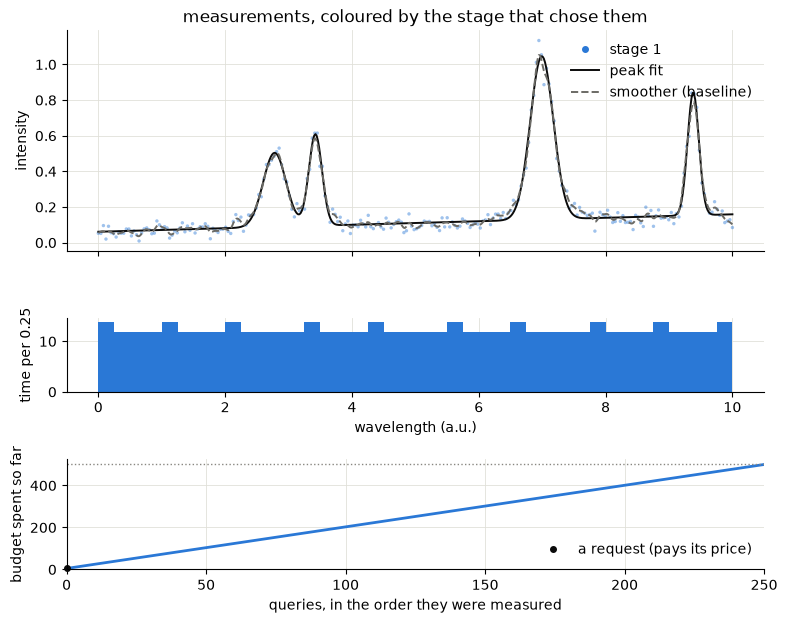

In [ ]:
def peak_model(p, x, k):
    """A tilted baseline plus k Gaussian peaks. p = [offset, slope, then (height, centre, width) per peak]."""
    out = p[0] + p[1] * (x - 5)
    for i in range(k):
        height, centre, width = p[2 + 3 * i: 5 + 3 * i]
        out = out + height * np.exp(-0.5 * ((x - centre) / width) ** 2)
    return out


def peak_surrogate(wl, t, v, max_peaks=6, narrowest=0.05):
    """Fit k = 1, 2, ... peaks to the data and keep the k with the best BIC."""
    smooth, uncertainty = smooth_surrogate(wl, t, v)
    if len(wl) < 20:
        return smooth, uncertainty
    pilot, _ = smooth_surrogate(wl, t, v, width=0.12)
    tops = [i for i in range(1, len(E) - 1) if pilot[i] > pilot[i - 1] and pilot[i] >= pilot[i + 1] and pilot[i] > 0.2]
    tops = sorted(tops, key=lambda i: -pilot[i])[:max_peaks]
    best = None
    for k in range(1, len(tops) + 1):
        start = [0.08, 0.0] + sum([[max(pilot[i] - 0.08, 0.2), E[i], 0.3] for i in sorted(tops[:k])], [])
        low = [0.0, -0.05] + [0.05, 0.0, narrowest] * k
        high = [0.3, 0.05] + [2.0, 10.0, 1.0] * k
        fit = least_squares(lambda p: (peak_model(p, wl, k) - v) * np.sqrt(t), start, bounds=(low, high))
        bic = len(wl) * np.log(2 * fit.cost / len(wl)) + len(start) * np.log(len(wl))
        if best is None or bic < best[0]:
            best = (bic, fit.x, k)
    if best is None:  # no peak found: fall back to the smoother
        return smooth, uncertainty
    return peak_model(best[1], E, best[2]), uncertainty


session = server.train_session(seed=7)
prediction = run(session, scan_policy, peak_surrogate)
print(session.submit(prediction))
show(session, {"peak fit": prediction, "smoother (baseline)": smooth_surrogate(*measured(session))[0]})

## 4. A policy that uses the surrogate

The scan never looks at the data it collects. A policy gets better by reading the surrogate. This one uses two stages: a coarse scan with part of the time, then the rest of the time spent where the surrogate's estimate is high. That is feedback: the second stage depends on the first stage's results.

{'accepted': True, 'rmse': 0.012767900510850368, 'reference_rmse': 0.01992023290156903, 'ratio': 0.6409513670818927, 'time_used': 499.9999999999981, 'measurements': 275, 'rounds': 2}


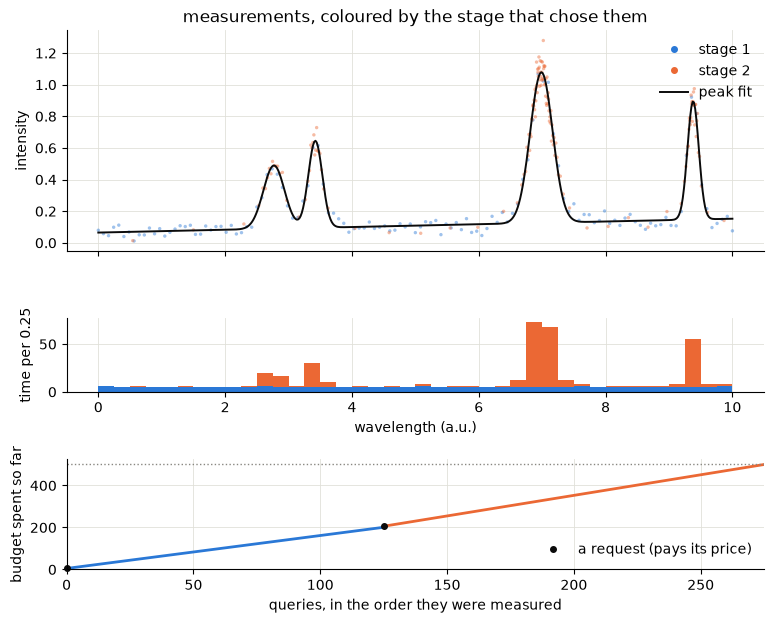

In [ ]:
def focus_policy(state, first_share=0.4, n1=125, n2=150):
    """Stage 1: a coarse scan with part of the time. Stage 2: the rest, where the estimate is high."""
    if state["stage"] >= 2:
        return None
    if state["stage"] == 0:
        spendable = (state["time_left"] - 2 * state["request_cost"]) * first_share
        return [(w, spendable / n1) for w in np.linspace(0, 10, n1)]
    weight = np.clip(state["estimate"], 0.05, None) ** 2
    wl = np.interp((np.arange(n2) + 0.5) / n2, np.cumsum(weight) / weight.sum(), E)
    spendable = state["time_left"] - state["request_cost"]
    return [(w, spendable / n2) for w in wl]


def focus_strategy(s):
    return run(s, focus_policy, peak_surrogate)


session = server.train_session(seed=7)
prediction = focus_strategy(session)
print(session.submit(prediction))
show(session, {"peak fit": prediction})

In [ ]:
sc.train_eval(server, focus_strategy, seeds=range(5))

 seed  queries  rounds   ratio
    0      275       2   0.769
    1      275       2   0.486
    2      275       2   0.467
    3      275       2   0.788
    4      275       2   0.553
        geometric mean   0.597


0.5973461829027704

## 5. Which piece matters?

A single score mixes the two pieces, so test them one at a time. This offline table tries each policy with each surrogate on 30 simulated spectra (`spectrum_sim` is the server's own simulator on your machine, see the next section). Lower is better; 1.0 is the baseline.

In [ ]:
def geomean(x):
    return float(np.exp(np.mean(np.log(x))))


policies = {"scan": scan_policy, "focus": focus_policy}
surrogates = {"smoother": smooth_surrogate, "peak fit": peak_surrogate}
print(f"{'':8}" + "".join(f"{name:>10}" for name in surrogates))
for p_name, policy in policies.items():
    row = [geomean(evaluate(lambda s: run(s, policy, surrogate), seeds=range(30))) for surrogate in surrogates.values()]
    print(f"{p_name:8}" + "".join(f"{r:10.3f}" for r in row))

          smoother  peak fit
scan         1.004     0.636
focus        1.438     0.550


The surrogate is the bigger lever here. The second stage helps the peak fit and hurts the smoother, so a policy and a surrogate have to suit each other, and that pair is what your grade measures. Try to work out why the smoother loses.

## 6. Train offline

A run is a sequential decision problem. The **state** is what you have measured plus the time left (and whatever your surrogate makes of it). An **action** is the next stage. The **reward** is the final score, for example `-log(ratio)`. You can plan it with **dynamic programming** (the surrogate's estimate and uncertainty are your belief about the spectrum; look ahead and pick the stage that is expected to help most), learn a policy with **reinforcement learning**, or tune a hand-made rule. Whatever you choose, only the two functions change: `surrogate` and `policy`.

`spectrum_sim` has the same spectra and noise as the server for the same seeds, the same budget and cost rules, and it is thousands of times faster than the network. Train there, then test on the server. Here one policy parameter, the share of time for the coarse scan, is tuned on simulated episodes:

In [ ]:
for share in (0.2, 0.4, 0.6, 0.8):
    ratios = evaluate(lambda s: run(s, partial(focus_policy, first_share=share), peak_surrogate), seeds=range(30))
    print(f"coarse scan gets {share:.0%} of the time: geometric mean ratio {geomean(ratios):.3f}")

coarse scan gets 20% of the time: geometric mean ratio 0.554
coarse scan gets 40% of the time: geometric mean ratio 0.550
coarse scan gets 60% of the time: geometric mean ratio 0.564
coarse scan gets 80% of the time: geometric mean ratio 0.555


With 30 spectra the geometric mean is only good to about 6%, so these four shares cannot be told apart. Use more spectra before you choose between close options.

The environment also shows what only the simulator can: the true error. That is what you would use to build a reward for RL, or to check a surrogate:

In [ ]:
env = SpectrumEnv()
obs = env.reset(seed=7)  # the same spectrum and noise as server train seed 7
obs, reward, done, info = env.step(scan_policy({"stage": 0, "time_left": obs["time_left"], "request_cost": env.request_cost}))
wl, t, v = obs["measurements"].T
for name, surrogate in surrogates.items():
    print(f"true error of the {name}:", round(env.error(surrogate(wl, t, v)[0]), 4))
print("time left:", round(obs["time_left"], 3), "| done:", done)

true error of the smoother: 0.0245
true error of the peak fit: 0.0146
time left: 0.0 | done: True


## 7. Your turn

Replace `my_surrogate` and `my_policy`; they start as the baseline, so an unchanged notebook scores about 1.0. Reuse the pieces above or build your own. Ideas: a surrogate with a better peak model, a Gaussian process, or a network you train on simulated spectra; a policy with more stages, one driven by the surrogate's uncertainty, a dynamic-programming rule, or a learned one. A strategy must leave enough time for every request it makes: each one pays `request_cost`.

In [ ]:
def my_surrogate(wl, t, v):
    return smooth_surrogate(wl, t, v)  # replace with your own model


def my_policy(state):
    return scan_policy(state)  # replace with your own decision rule


def my_strategy(s):
    return run(s, my_policy, my_surrogate)

In [ ]:
sc.train_eval(server, my_strategy, seeds=range(5))  # on the server
print("offline, 50 spectra: geometric mean ratio", round(geomean(evaluate(my_strategy, seeds=range(50))), 3))

 seed  queries  rounds   ratio
    0      250       1   0.907
    1      250       1   0.993
    2      250       1   0.825
    3      250       1   1.115
    4      250       1   1.020
        geometric mean   0.967
offline, 50 spectra: geometric mean ratio 1.003


## 8. Test: the cell you hand in

Run this cell last, after **Restart and run all**. It first checks your strategy once on a training spectrum, then runs it on each of the 10 hidden spectra and prints your result table with a verification code. You have 3 attempts, and the same code always gives the same result. Do not edit what it prints.

In [ ]:
my_name = "Surname Name"  # your surname and name

sc.run_test(server, my_strategy, name=my_name)